In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress, t
from arch.bootstrap import MovingBlockBootstrap

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib.ticker import PercentFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def draw_bracket(ax, x0, x1, y, h=0.0025, lw=1.2, color='k', text=None, text_offset=0.0008):
    """
    x0, x1: 括号覆盖的左右 x（数据坐标，和 bar 的 x_pos 一致）
    y: 括号底部 y（数据坐标）
    h: 括号竖线高度（向上）
    """
    ax.vlines([x0, x1], y, y-h, colors=color, linewidth=lw, clip_on=False)

    ax.hlines(y-h, x0, x1, colors=color, linewidth=lw, clip_on=False)
    if text is not None:
        ax.text((x0 + x1)/2, y-h-text_offset, text,
                ha='center', va='top', color=color, fontsize=11, clip_on=False)

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def draw_vertical_annotation(ax, x, y_start, y_end, text, color='black', arrow_type='bar'):
    """
    在图上的指定 x 位置，从 y_start 到 y_end 画垂直标注线和文字。
    arrow_type: 'bar' (工字形) 或 'arrow' (双箭头)
    """
    mid_y = (y_start + y_end) / 2
    
    if arrow_type == 'bar':
        # 画工字形线 (|-|)
        # 竖线
        ax.plot([x, x], [y_start, y_end], color=color, linewidth=1, linestyle='-')
        # 上横杠
        ax.plot([x - 0.1, x + 0.1], [y_end, y_end], color=color, linewidth=1)
        # 下横杠
        ax.plot([x - 0.1, x + 0.1], [y_start, y_start], color=color, linewidth=1)
    
    elif arrow_type == 'arrow':
        # 使用 annotate 画双箭头
        ax.annotate('', xy=(x, y_start), xytext=(x, y_end),
                    arrowprops=dict(arrowstyle='<->', color=color, lw=1))
    
    # 添加文字 (稍微向左偏移一点，避免压线，并垂直居中)
    ax.text(x - 0.7, mid_y, text, ha='center', va='center', fontsize=10, color=color)

def cal_MBB_corr_contribusion(x, y, boot_times, block_len, x_num):
    """
    该函数用来使用Moving Block Bootstrapping方法计算序列对于
    例如先有两个序列y1和y2，其中y1 = x1+x2+x3 想要的到针对y1与y2之间相关中，不同变量x的贡献
    输入y为一维数据，x中每一行为不同变量的数据
    一般选择boot_times为1000
    block_len为12
    """
    x = np.transpose(x)
    y = np.transpose(y)
    bs = MovingBlockBootstrap(block_len, x, y = y)
    num = 0

    data_boot = np.zeros((x_num, boot_times))
    # bootstrap计算显著性区间 1 sigma
    for boot in bs.bootstrap(boot_times):
        bs_x = np.squeeze(boot[0][0])
        bs_y = boot[1]['y']

        ## 计算变量和的标准差
        bs_x_sum = np.sum(bs_x, axis=1)
        std_x_sum = np.std(bs_x_sum)

        for num_exp in range(x_num):
            x_temp = bs_x[:, num_exp]
            r = cal_pearson_corr(bs_y, x_temp)
            std_x = np.std(x_temp)

            data_boot[num_exp, num] = r * std_x / std_x_sum
            
        num = num+1

    params = np.full(x_num, np.nan)
    std_sum = np.std(np.sum(x, axis=1))
    for num_exp in range(x_num):
        params[num_exp] = cal_pearson_corr(y, x[:, num_exp]) * np.std(x[:, num_exp]) / std_sum
    param_std = np.std(data_boot, axis=1)
    
    return param_std, params

def cal_pearson_corr(y, x):
    # 确保 x 和 y 是 NumPy 数组
    y = np.array(y)
    x = np.array(x)

    # 去中心化
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    x_diff = x - x_mean
    y_diff = y - y_mean

    # 相关系数公式
    numerator = np.sum(x_diff * y_diff)
    denominator = np.sqrt(np.sum(x_diff**2) * np.sum(y_diff**2))

    r = numerator / denominator
    return r

In [3]:
# --- 1. 参数与数据字典初始化 ---
Part2_dict = {}
with open('/public/home/zhujw/work/guoly/code/Paper-2-NH-Transport/Data-pre/GC-output/gc-mask-data.pkl', 'rb') as f:
    model_dict = pickle.load(f)

region_list = ['SH Ocean', 'SH Temperate', 'SH Tropics', 'NH Tropics', 'NH Temperate', 'Boreal'][::-1]
select_region = region_list[:3]
exp_list = ['control', 'land', 'ocean', 'fossil', 'wind']

period = 120
start_year, end_year = 1982, 2022

n_reg = len(region_list)
n_sel = len(select_region)
n_exp = len(exp_list) - 1
years_count = end_year - start_year

# --- 2. 主循环：模型运算处理 ---
for model, info in model_dict.items():
    smooth_con = info['smooth_cycle_control'][::-1]
    smooth_data = info['smooth_cycle_exp'][::-1, ::-1, -1] # 只取mask试验
    time_cycle = info['time_cycle']
    
    # 获取目标时间范围的掩码 (避免循环内反复判断)
    time_mask = (time_cycle >= start_year) & (time_cycle < end_year)
    
    # ==========================================
    # Phase A: 计算不同区域大气传输提供的季节循环
    # ==========================================
    smooth_exp = np.zeros_like(smooth_data)
    
    for i in range(n_reg):         # region_off
        for j in range(n_reg):     # region_target
            if i == j:
                smooth_exp[i, j] = smooth_data[i, j]
            else:
                smooth_exp[i, j] = smooth_con[j] - smooth_data[i, j]
    
    # 截取目标时间段后重塑并求年平均
    annual_mean = np.mean(
        smooth_exp[..., time_mask].reshape(n_reg, n_reg, years_count, period), 
        axis=-2
    )
    annual_control = np.mean(
        smooth_con[:, time_mask].reshape(n_reg, years_count, period), 
        axis=-2
    )
    info['annual_mean'] = annual_mean
    info['annual_control'] = annual_control

    # 计算目标区域的 wind source 和 import
    # index: -1 对应风场影响, -n_sel: 获取选择的区域
    import_annual = np.swapaxes(annual_mean[:, :n_sel, :] , 0, 1)  # (region, source_region, time)
    export_annual = annual_mean[:n_sel, :, :]                      # (region, target_region, time)

    info['import_annual'] = import_annual
    info['export_annual'] = export_annual

    # ==========================================
    # Phase B: 计算 wind 之中不同分区的相互贡献
    # ==========================================
    # wind 中对各目标区的自身贡献总和 (自身对应自身)
    import_sum = np.zeros((n_sel, period))
    export_sum = np.zeros((n_sel, period))
    for i in range(n_sel):
        import_sum[i] = annual_mean[i, i]
        export_sum[i] = export_annual[i].sum(axis=0) - export_annual[i, i]

    # 南半球合并为1行，北半球区域保持独立
    import_line = np.concatenate([import_annual[:, :n_sel], import_annual[:, n_sel:].sum(axis=1, keepdims=True)], axis=1)  # (region, source_region, time)
    export_line = np.concatenate([export_annual[:, :n_sel], export_annual[:, n_sel:].sum(axis=1, keepdims=True)], axis=1) 

    # 初始化统计输出数组
    corr_import, corr_export = np.zeros((n_sel, 3)), np.zeros((n_sel, 3))
    corr_import_std, corr_export_std = np.zeros_like(corr_import), np.zeros_like(corr_export)
    corr_import_p, corr_export_p = np.zeros(n_sel), np.zeros(n_sel)
    corr_import_var, corr_export_var = np.zeros(n_sel), np.zeros(n_sel)

    # 分别对 select_region 逐个进行相关性和贡献率分析
    for num_area in range(n_sel):
        # --- 处理 Import ---
        import_sum_temp = import_sum[num_area]
        # 删除自身区域的输入，提取外部输入的贡献
        import_temp = np.delete(import_line[num_area], num_area, axis=0) 
        
        corr_import_var[num_area], corr_import_p[num_area] = pearsonr(np.sum(import_temp, axis=0), import_sum_temp)
        
        # 调用外部方法 cal_MBB_corr_contribusion
        corr_import_std[num_area], corr_import[num_area] = cal_MBB_corr_contribusion(
            import_temp, import_sum_temp, 
            100, int(period/4), int(import_temp.shape[0])
        )

        # --- 处理 Export ---
        export_sum_temp = export_sum[num_area]
        # 删除自身区域的输出，提取对外部输出的贡献
        export_temp = np.delete(export_line[num_area], num_area, axis=0) 
        
        corr_export_var[num_area], corr_export_p[num_area] = pearsonr(np.sum(export_temp, axis=0), export_sum_temp)
        
        # 调用外部方法 cal_MBB_corr_contribusion
        corr_export_std[num_area], corr_export[num_area] = cal_MBB_corr_contribusion(
            export_temp, export_sum_temp, 
            100, int(period/4), int(export_temp.shape[0])
        )
        
    info['corr_import_var'] = corr_import_var
    info['corr_import_p'] = corr_import_p
    info['corr_import_std'] = corr_import_std
    info['corr_import'] = corr_import

    info['corr_export_var'] = corr_export_var
    info['corr_export_p'] = corr_export_p
    info['corr_export_std'] = corr_export_std
    info['corr_export'] = corr_export
    
    # 写入结果字典
    Part2_dict[model] = info

# --- 3. 释放原始输入以节省内存 ---
del model_dict

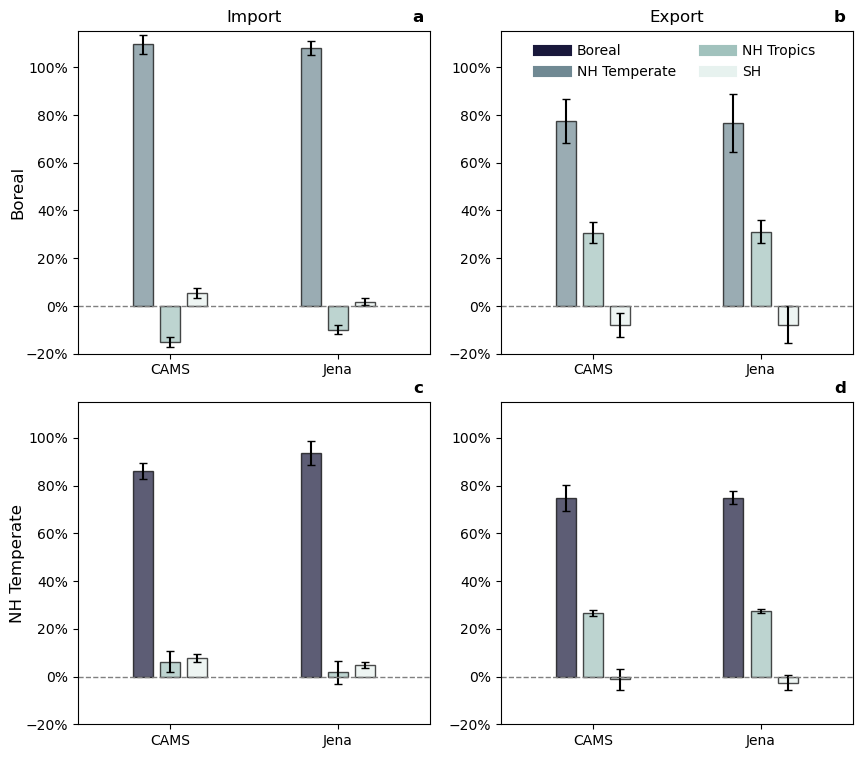

In [4]:
# 画图
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 1], height_ratios=[1, 1], wspace=0.2, hspace=0.15)
fig = plt.figure(figsize=(10, 9))
axs = np.empty((2, 2), dtype=object)

for i in range(2):
    for j in range(2):
        axs[i, j] = fig.add_subplot(gs[i, j])

region_list = np.array(['Boreal', 'NH Temperate', 'NH Tropics', 'SH'])
color_list = np.array(['#19183B', '#708993', '#A1C2BD', '#E7F2EF'])

r_idx = [0, 1]
for num_area in r_idx:
    r_list_temp = np.delete(region_list, num_area)  # 删除当前区域，获取其他区域列表
    c_list_temp = np.delete(color_list, num_area)    # 删除当前区域对应的颜色，获取其他颜色列表

    import_value, import_std = [], []
    export_value, export_std = [], []

    for model, info in Part2_dict.items():
        import_value.append(info['corr_import'][num_area])
        import_std.append(info['corr_import_std'][num_area])
        export_value.append(info['corr_export'][num_area])
        export_std.append(info['corr_export_std'][num_area])

    for i, ax in enumerate(axs[num_area, :]):
        if i == 0:
            data_value = np.array(import_value)*100
            data_std = np.array(import_std)*100
        else:
            data_value = np.array(export_value)*100
            data_std = np.array(export_std)*100

        x_group = ['CAMS', 'Jena']

        vals_grp = data_value.reshape(2, 3)  # (2组, 3类)
        errs_grp = data_std.reshape(2, 3)

        group_gap = 1.5  # >1 会增加组间距（可调：1.2~1.8）
        x = np.arange(len(x_group)) * group_gap

        bar_w = 0.18          # 柱子更窄一点
        inner_gap = 1.35      # 组内“间距系数”，越大同组越松（可调：1.1~1.8）
        offsets = (np.arange(3) - 1) * bar_w * inner_gap 

        for k in range(3):
            ax.bar(
                x + offsets[k],
                vals_grp[:, k],
                yerr=errs_grp[:, k],
                width=bar_w,
                color=c_list_temp[k],
                edgecolor='black',
                capsize=3,
                alpha=0.7,
                label=r_list_temp[k]
            )

        ax.set_xticks(x)
        ax.set_xticklabels(x_group)
        ax.axhline(0, color='grey', linewidth=1, linestyle='--')
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        pad = 0.55 * group_gap
        ax.set_xlim(x[0] - pad, x[-1] + pad)
        ax.set_ylim(-20, 115)

custom_lines = [Line2D([0], [0], color=color_list[k], lw=8) for k in range(4)]
axs[0, 1].legend(custom_lines, region_list, loc='upper center', ncol=2, frameon=False)

xlabels = ['Import', 'Export']
ylabels = ['Boreal', 'NH Temperate']
letters = ['a', 'b', 'c', 'd']
for i in range(2):
    axs[i, 0].text(-0.15, 0.5, ylabels[i], va='center', ha='right', 
                   rotation=90, fontsize=12, transform=axs[i, 0].transAxes)
    axs[0, i].text(0.5, 1.02, xlabels[i], va='bottom', ha='center',
                   fontsize=12, transform=axs[0, i].transAxes)
    for j in range(2):
        axs[i, j].text(0.98, 1.02, letters[i*2+j], va='bottom', ha='right',
                       fontsize=12, transform=axs[i, j].transAxes, fontweight='bold')

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-5-GC-transport-source.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

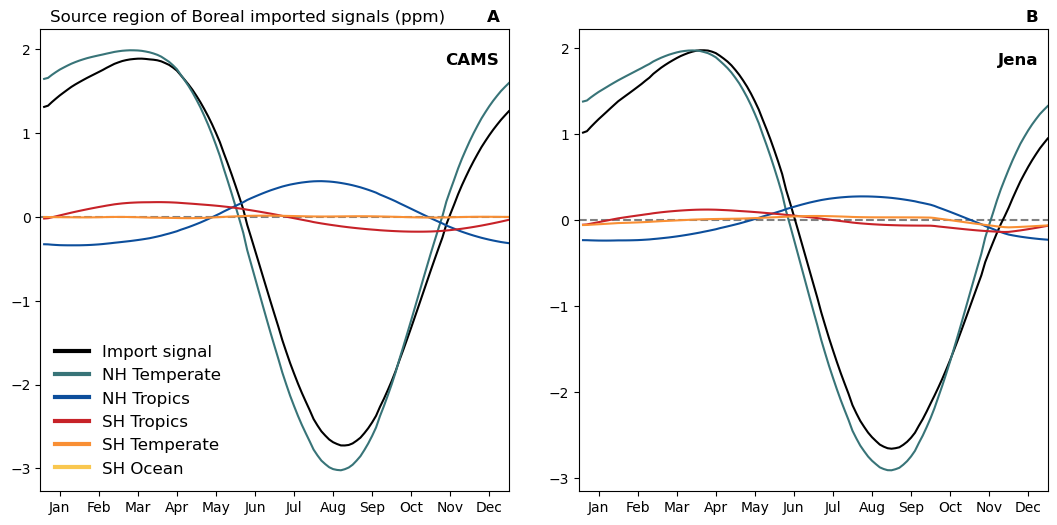

In [6]:
# Imported SC
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1], height_ratios=[1], wspace=0.15)
fig = plt.figure(figsize=(13, 6))
axs = np.empty((2), dtype=object)
color_list = np.array(['black', '#387478', '#0c4e9b', '#c72228', '#f98f34', '#f9c74f', '#6a994e'])
region_list = ['Import signal', 'NH Temperate', 'NH Tropics', 'SH Tropics', 'SH Temperate', 'SH Ocean']

for i in range(2):
    axs[i] = fig.add_subplot(gs[i])

for n_m, (model, info) in enumerate(Part2_dict.items()):
    import_annual = info['import_annual'][0, 1:]
    import_annual = np.vstack([import_annual.sum(axis=0), import_annual])
    ax = axs[n_m]

    ax.axhline(0, color='gray', linewidth=1.5, linestyle='--')
    for j in range(5):
        ax.plot(np.arange(1, period + 1), import_annual[j], color=color_list[j])
    months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    xticks = np.linspace(period//12/2, period - period//12/2, 12)
    ax.set_xticks(xticks)
    ax.set_xticklabels(months)
    # 设置x轴范围保持一致
    ax.set_xlim(0, period)

custom_lines = [Line2D([0], [0], color=color_list[k], lw=3) for k in range(6)]

axs[0].legend(custom_lines, region_list, loc='lower left', 
              ncol=1, frameon=False, fontsize=12)
letters = ['A', 'B']
model_list = list(Part2_dict.keys())
for i in range(2):
    ax = axs[i]
    ax.text(0.98, 1.01, letters[i], va='bottom', ha='right',
            fontsize=12, transform=ax.transAxes, fontweight='bold')
    ax.text(0.98, 0.95, model_list[i], va='top', ha='right',
            fontsize=12, transform=ax.transAxes, fontweight='bold')

axs[0].text(0.02, 1.01, 'Source region of Boreal imported signals (ppm)', va='bottom', ha='left',
        fontsize=12, transform=axs[0].transAxes)

plt.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-method-source-signals.png',
            dpi=500)